# Robert Rossi - Data Analysis and Visualization

In [3]:
import micropip
await micropip.install("seaborn")

In [4]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#make the plots look cleaner
sns.set_theme(style="whitegrid")

#display more columns
pd.set_option("display.max_columns", None)

In [6]:
#load the cleaned dataset
df = pd.read_csv("modelling.csv")

#preview data
df.head()

,job_id,job_title,jobs_group,seniority,remote,company_clean,company,city,state_x,annual_low,annual_mean,annual_high,bls_occ_code,skills,skills_count,company_co,sector,sector_group,revenue_band,revenue_rank,employee_band,employee_rank,company_score,reviews_count,state_y,state_abbr,occ_title,total_employed,bls_annual_mean,bls_annual_median,bls_p10,bls_p90,state_name,pce_2023_in_millions
0,sj_1e37379f40861c74,Business Analyst,Business Analyst,Unspecified,On-site,Cybercoders,CyberCoders,Torrington,CT,80000.0,95000.0,110000.0,13-1111,[],0,CyberCoders,Human Resources,Human Resources,L,5.0,M,4.0,3.9,82.0,Connecticut,CT,Management Analysts,"9,570",115530.0,102960.0,64420.0,175156.8,Connecticut,235580.4
1,job_df29ae66361809be,Business Systems Analyst - Remote Work Opportu...,Business Analyst,Unspecified,Remote,Culinary Institute Of America,Culinary Institute of America,Hyde Park,NY,70000.0,75000.0,80000.0,13-1111,"['Access', 'Office', 'SQL', 'Bachelor', '.NET'...",6,Culinary Institute of America,NaN,NaN,NaN,NaN,NaN,NaN,3.7,74.0,New York,NY,Management Analysts,"59,640",126450.0,106100.0,64460.0,206398.4,New York,1248145.3
2,job_d99cde7d90678e47,Training and placement for Business Analyst,Business Analyst,Unspecified,On-site,Precision Technologies Corp,Precision Technologies Corp,Milltown,NJ,66240.0,69920.0,73600.0,13-1111,"['Excel', 'SQL']",2,precision technologies corp,Software Development,Information Technology,NaN,NaN,NaN,NaN,3.7,7.0,New Jersey,NJ,Management Analysts,"19,300",122840.0,103770.0,66060.0,182312.0,New Jersey,592882.2
3,job_628abdee3ad81cfc,"Lead Business Analyst, ASC Customer Reporting ...",Financial Analyst,Lead,Remote,Stryker,Stryker,NaN,MI,176800.0,176800.0,176800.0,13-2051,['Bachelor'],1,Stryker,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Michigan,MI,Financial and Investment Analysts,"7,520",95710.0,83920.0,61040.0,130353.6,Michigan,524045.1
4,job_7fb39d213f0cd66d,Sr. Analyst-Business Intelligence,Business Intelligence,Senior,Hybrid,Verizon,Verizon,Basking Ridge,NJ,70000.0,99500.0,129000.0,15-2031,"['Excel', 'Tableau', 'SQL', 'Bachelor', 'Pytho...",10,Verizon,Telecommunications,Information Technology,XXXL,8.0,XXXL,8.0,3.9,31584.0,New Jersey,NJ,Operations Research Analysts,"3,890",108990.0,102140.0,65400.0,158496.0,New Jersey,592882.2


In [7]:
#show dataset shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

#show column names
print("\nColumn names:")
print(df.columns.tolist())

#show missing values
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Rows: 36452
Columns: 34

Column names:
['job_id', 'job_title', 'jobs_group', 'seniority', 'remote', 'company_clean', 'company', 'city', 'state_x', 'annual_low', 'annual_mean', 'annual_high', 'bls_occ_code', 'skills', 'skills_count', 'company_co', 'sector', 'sector_group', 'revenue_band', 'revenue_rank', 'employee_band', 'employee_rank', 'company_score', 'reviews_count', 'state_y', 'state_abbr', 'occ_title', 'total_employed', 'bls_annual_mean', 'bls_annual_median', 'bls_p10', 'bls_p90', 'state_name', 'pce_2023_in_millions']

Missing values:
revenue_rank         19702
revenue_band         19702
employee_band        13659
employee_rank        13659
company_score         9104
reviews_count         9104
sector                7705
sector_group          7705
bls_p90               5791
city                   838
company_co              87
company                  9
company_clean            9
bls_annual_median        0
bls_annual_mean          0
occ_title                0
state_abbr            

In [8]:
#summary statistics for numeric columns
df.describe()

,annual_low,annual_mean,annual_high,skills_count,revenue_rank,employee_rank,company_score,reviews_count,bls_annual_mean,bls_annual_median,bls_p10,bls_p90,pce_2023_in_millions
count,36452.000000,36452.000000,36452.000000,36452.000000,16750.000000,22793.000000,27348.000000,27348.000000,36452.000000,36452.000000,36452.000000,30661.000000,3.645200e+04
mean,89050.796659,102667.062372,116283.328086,3.819406,5.177194,5.911771,3.648539,2807.415058,128421.290464,116018.192692,69090.210962,176952.398108,1.047854e+06
std,36618.955235,42515.766679,51383.633216,2.606804,2.543221,2.276280,0.629376,13250.427718,33205.627632,30301.140220,16406.478427,30799.990479,8.438075e+05
min,14720.000000,15000.000000,15000.000000,0.000000,0.000000,0.000000,1.000000,1.000000,63640.000000,52010.000000,31610.000000,97011.200000,3.325680e+04
25%,64400.000000,74000.000000,81492.000000,2.000000,3.000000,4.000000,3.400000,14.750000,102590.000000,95760.000000,57990.000000,149468.800000,3.748801e+05
50%,80800.000000,94650.000000,106019.000000,3.000000,6.000000,6.000000,3.700000,122.000000,121310.000000,108580.000000,66060.000000,174990.400000,5.961627e+05
75%,106720.000000,122500.000000,139840.000000,5.000000,8.000000,8.000000,4.000000,1031.000000,143330.000000,133690.000000,77200.000000,206398.400000,1.595278e+06
max,425000.000000,486000.000000,600000.000000,22.000000,8.000000,8.000000,5.000000,247915.000000,241150.000000,215430.000000,127720.000000,237848.000000,2.526290e+06


In [27]:
#set important column names
salary_col = "annual_mean"              # actual company/job salary
state_col = "state_x"                   # job state
job_col = "job_title"                   # specific job title
job_group_col = "jobs_group"            # broader job category
company_col = "company"                 # company name
sector_col = "sector_group"             # company sector
cost_col = "pce_2023_in_millions"       # rough cost/living proxy
expected_salary_col = "bls_annual_mean" # BLS expected salary
label_col = "fairness_label"
fairness_col = "fairness_index"

### Create Fairness Index

In [10]:
#fairness index = actual job salary / expected BLS salary
df["fairness_index"] = df[salary_col] / df[expected_salary_col]

#label salaries based on fairness index
def label_fairness(x):
    if pd.isna(x):
        return np.nan
    elif x < 0.9:
        return "Underpaid"
    elif x <= 1.1:
        return "Fair"
    else:
        return "Generous"

df["fairness_label"] = df["fairness_index"].apply(label_fairness)

df[["job_title", "company", "state_x", "annual_mean", "bls_annual_mean", "fairness_index", "fairness_label"]].head()

,job_title,company,state_x,annual_mean,bls_annual_mean,fairness_index,fairness_label
0,Business Analyst,CyberCoders,CT,95000.0,115530.0,0.822297,Underpaid
1,Business Systems Analyst - Remote Work Opportu...,Culinary Institute of America,NY,75000.0,126450.0,0.593120,Underpaid
2,Training and placement for Business Analyst,Precision Technologies Corp,NJ,69920.0,122840.0,0.569196,Underpaid
3,"Lead Business Analyst, ASC Customer Reporting ...",Stryker,MI,176800.0,95710.0,1.847247,Generous
4,Sr. Analyst-Business Intelligence,Verizon,NJ,99500.0,108990.0,0.912928,Fair


### Graph 1: Salary Distribution
##### This is a graph of the distribution of company reported annual salaries. It shows where most of the salaries are concentrated and outliers. THe salaries appear to cluster around 70k-120k and it is skewed to the right which represent the fewer jobs with higher salaries

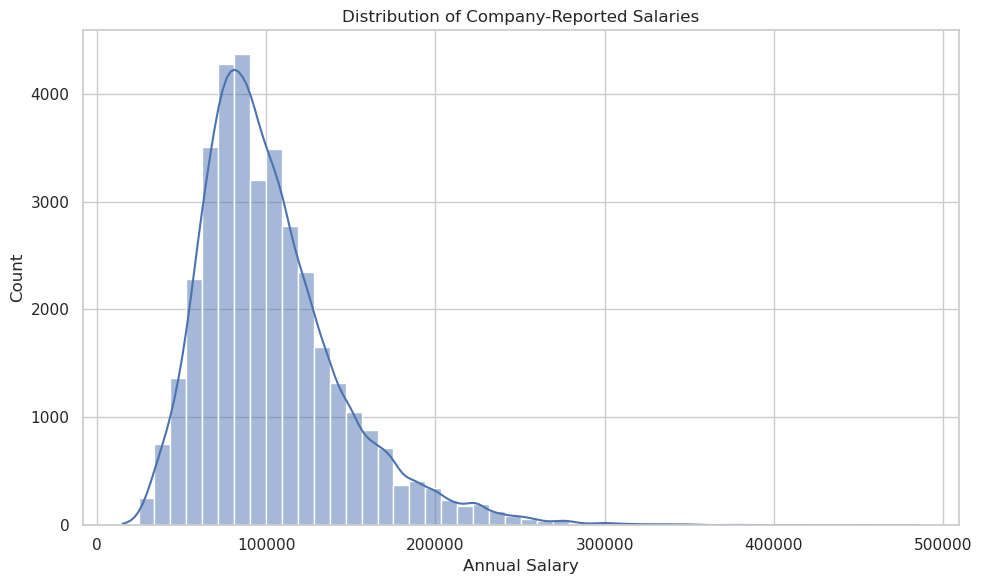

In [29]:
#salary distribution graph 
#keeps rows where salary column has real value
salary_data = df[df[salary_col].notna()]

plt.figure(figsize=(10, 6))
#makes histogram of company reported salaries with smooth curve
sns.histplot(salary_data[salary_col], bins=50, kde=True)

plt.title("Distribution of Company-Reported Salaries")
plt.xlabel("Annual Salary")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### Graph 2: Log Salary Distribution
##### This is a graph of the salary distribution after converting annual salaries to log10 values. This makes the distribution easier to analyze because it reduces the effect of  outliers and makes the salary pattern look more balanced.

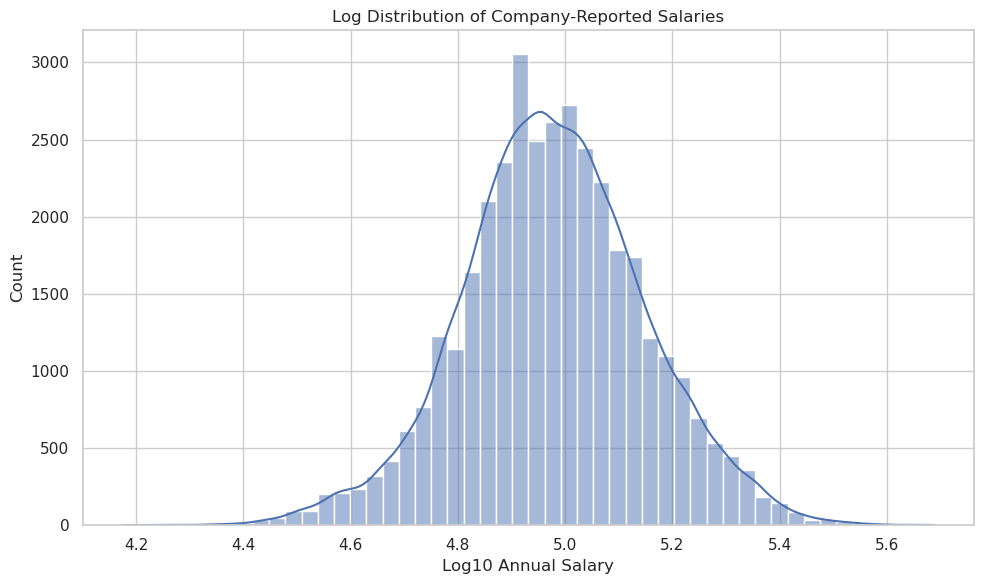

In [30]:
#only keeps rows where salary is > 0 because can't take log10 of 0 or negative values
salary_data = df[df[salary_col] > 0].copy()
#new column that stores log10 version of annual salary
salary_data["log_salary"] = np.log10(salary_data[salary_col])

plt.figure(figsize=(10, 6))
#creates historgram of log10 salaries with smooth curve
sns.histplot(salary_data["log_salary"], bins=50, kde=True)

plt.title("Log Distribution of Company-Reported Salaries")
plt.xlabel("Log10 Annual Salary")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### Graph 3: Average Salary by State
##### These graphs show the 10 states with the highest and lowest average company reported salaries.

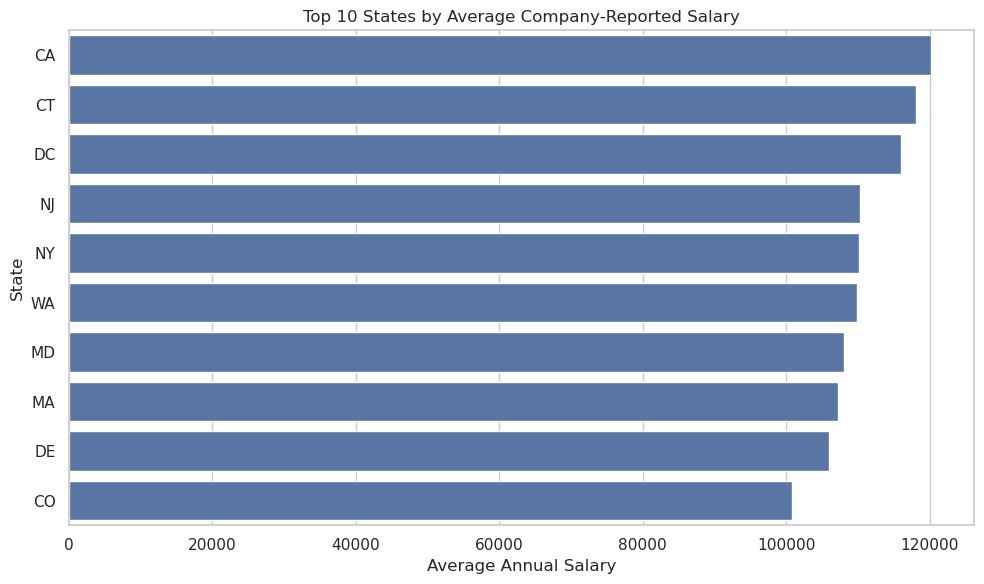

In [31]:
#top 10 states by average company salary
#groups data by state and calculates mean salary for each
state_salary = (
    df.groupby(state_col)[salary_col]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
#creates horizontal bar chart with average salary and state names
sns.barplot(x=state_salary.values, y=state_salary.index)

plt.title("Top 10 States by Average Company-Reported Salary")
plt.xlabel("Average Annual Salary")
plt.ylabel("State")

plt.tight_layout()
plt.show()

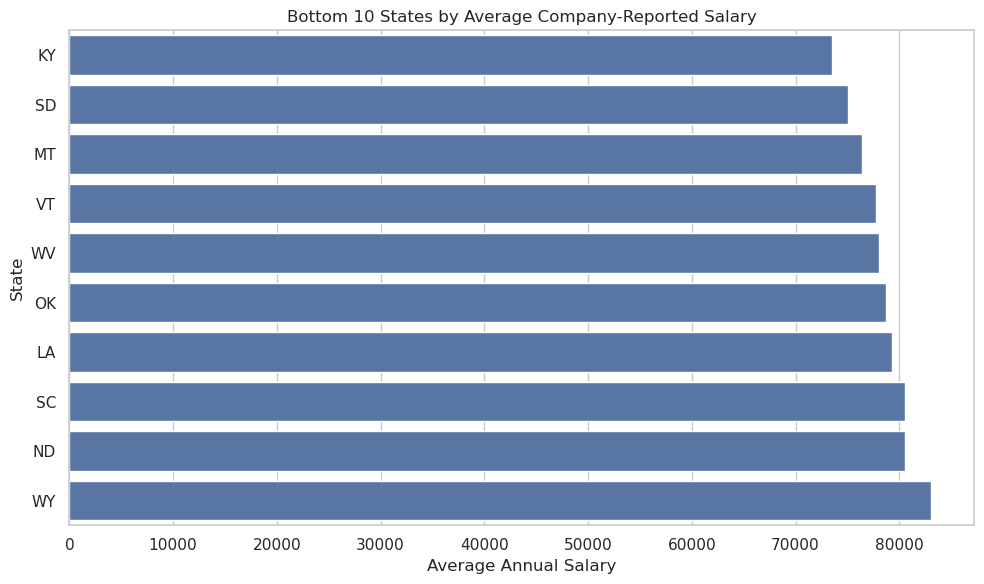

In [32]:
#bottom 10 states by average company salary
#group data by state and calculate mean salary for each
state_salary_bottom = (
    df.groupby(state_col)[salary_col]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

plt.figure(figsize=(10, 6))
#creates horizontal bar chart with average salary and states
sns.barplot(x=state_salary_bottom.values, y=state_salary_bottom.index)

plt.title("Bottom 10 States by Average Company-Reported Salary")
plt.xlabel("Average Annual Salary")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### Graph 4: Salary vs BLS Expected Salary
##### This graph compares company reported salaries to the BLS expected salaries for similar jobs. The dashed line represents where the company salary would exactly match the expected salary, while points above the line are more generous and points below the line are underpaid.

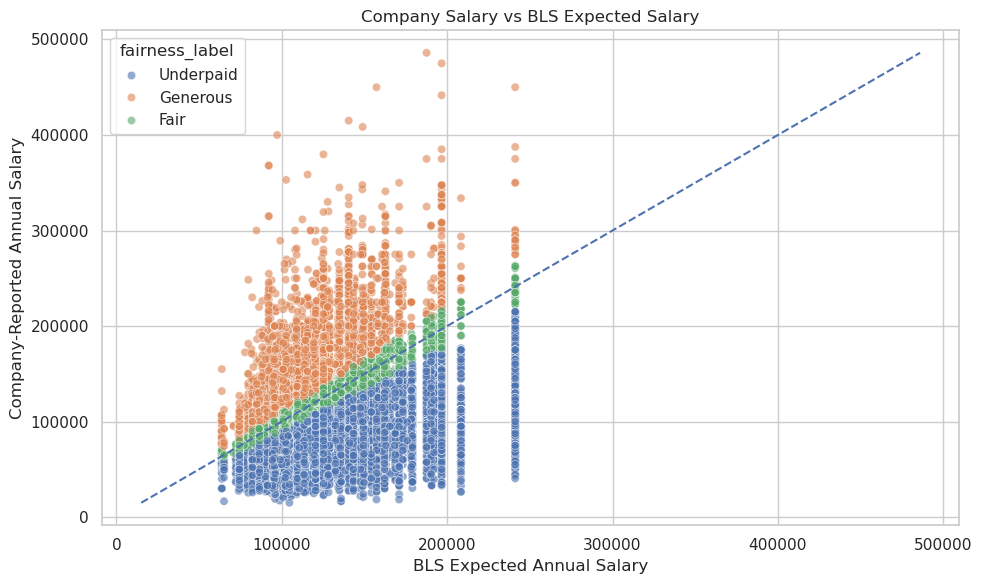

In [33]:
#actual company salary vs BLS expected salary
#removes rows with missing salary, expected salary, or fairness label values
plot_df = df[[salary_col, expected_salary_col, "fairness_label"]].dropna()

plt.figure(figsize=(10, 6))

#create scatter plot comparing expected salary to company reported salary, hue colors points by fairness category
sns.scatterplot(
    data=plot_df,
    x=expected_salary_col,
    y=salary_col,
    hue="fairness_label",
    alpha=0.6    #makes points transparent so you can see when points overlap
)

#reference line where actual salary = expected salary
min_val = min(plot_df[expected_salary_col].min(), plot_df[salary_col].min())
max_val = max(plot_df[expected_salary_col].max(), plot_df[salary_col].max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.title("Company Salary vs BLS Expected Salary")
plt.xlabel("BLS Expected Annual Salary")
plt.ylabel("Company-Reported Annual Salary")

plt.tight_layout()
plt.show()

### Graph 5: Fairness Index Distribution
##### This graph shows the distribution of the salary fairness index which compares company-reported salary to the BLS expected salary. Values below 0.9 suggest underpaid salaries, values between 0.9 and 1.1 are closer to fair, and values above 1.1 suggest more generous salaries.

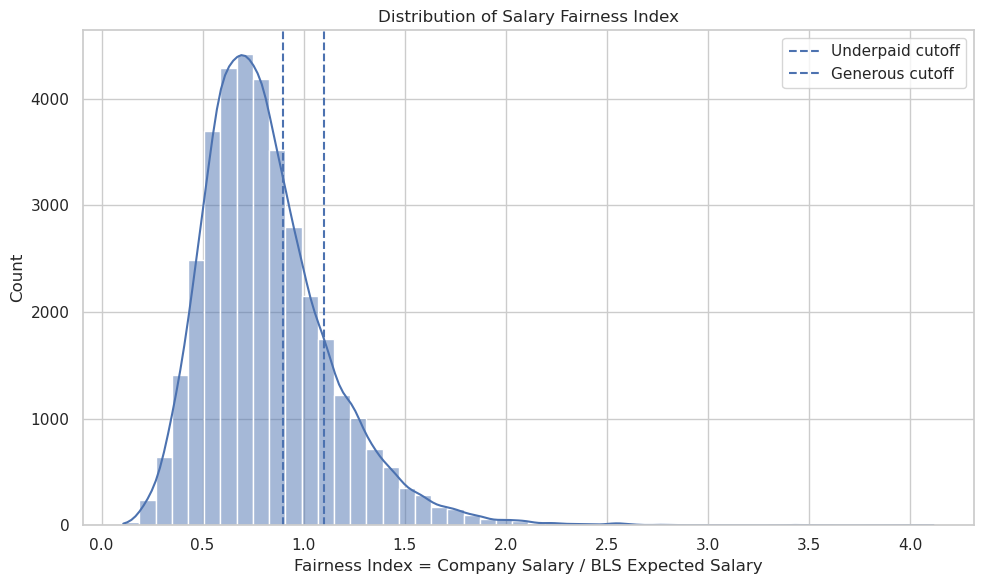

In [34]:
plt.figure(figsize=(10, 6))
#makes histogram of fairness index values
sns.histplot(df["fairness_index"].dropna(), bins=50, kde=True)

#vertical line at 0.9, values below this are underpaid
plt.axvline(0.9, linestyle="--", label="Underpaid cutoff")
#vertical line at 1.1, values above this are overpaid
plt.axvline(1.1, linestyle="--", label="Generous cutoff")

plt.title("Distribution of Salary Fairness Index")
plt.xlabel("Fairness Index = Company Salary / BLS Expected Salary")
plt.ylabel("Count")
plt.legend()

plt.tight_layout()
plt.show()

### Graph 6: Fairness Category Counts
##### This graph shows how many jobs fall into the three fairness categories. It shows us that most jobs in the dataset are underpaid compared to the BLS expected salary.

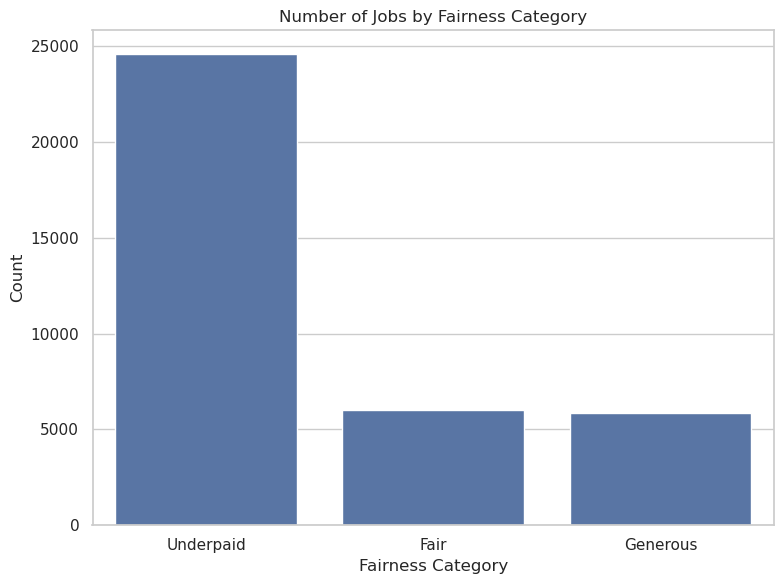

In [35]:
plt.figure(figsize=(8, 6))

#creates count plot that shows how many jobs are in each fairness category
sns.countplot(
    data=df,
    x="fairness_label",
    order=["Underpaid", "Fair", "Generous"]
)

plt.title("Number of Jobs by Fairness Category")
plt.xlabel("Fairness Category")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### Graph 7: Average Fairness by State
##### These graphs shows the 10 states with the highest and lowest average fairness index. A higher fairness index means company-reported salaries are closer to or higher than the BLS expected salary for similar jobs and a lower one means to lower than the expected salary.

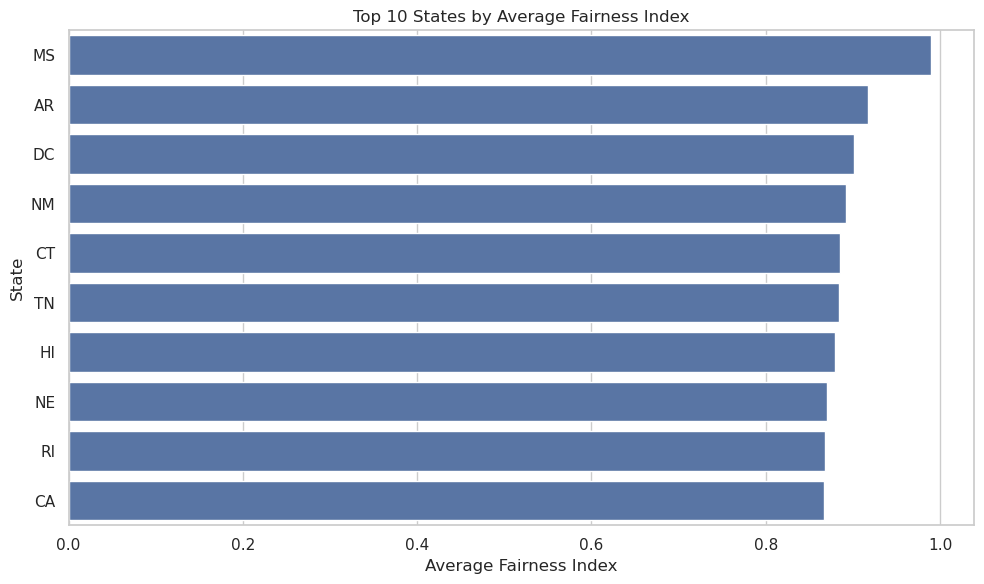

In [36]:
#top 10 states by fairness index
#group data by state and calculate average fairness index for each
state_fairness = (
    df.groupby(state_col)["fairness_index"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
#horizontal bar chart with fairness index and state names
sns.barplot(x=state_fairness.values, y=state_fairness.index)

plt.title("Top 10 States by Average Fairness Index")
plt.xlabel("Average Fairness Index")
plt.ylabel("State")

plt.tight_layout()
plt.show()

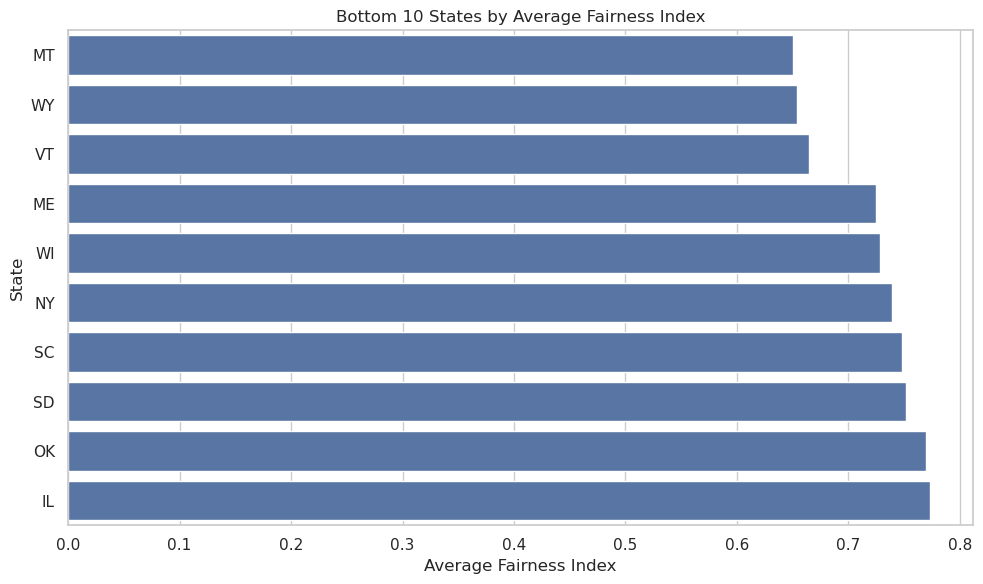

In [37]:
#bottom 10 states by fairness index
#group data by state and calculate average fairness index for each
state_fairness_bottom = (
    df.groupby(state_col)["fairness_index"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

plt.figure(figsize=(10, 6))
#horizontal bar chart with fairness index and state names
sns.barplot(x=state_fairness_bottom.values, y=state_fairness_bottom.index)

plt.title("Bottom 10 States by Average Fairness Index")
plt.xlabel("Average Fairness Index")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### Graph 8: Salary vs Cost-of-Living Proxy
##### This graph compares each state’s average company-reported salary to its PCE value which is used as a cost of living/economic activity proxy. Each point represents a state and larger points represent states with more job listings in the dataset.

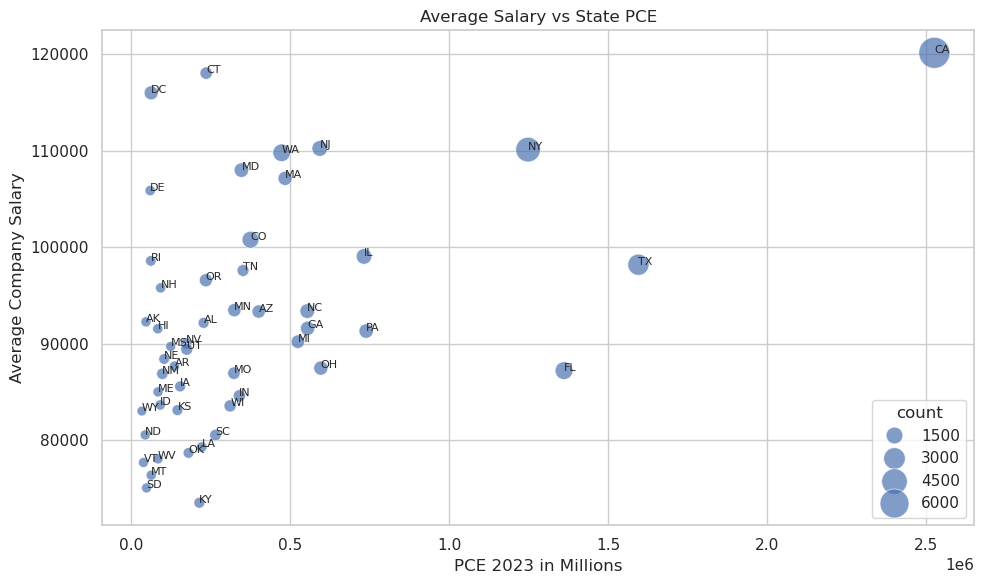

In [38]:
#state level summary table where each row represents one state instead of one job listing
state_summary = (
    df.groupby(state_col)
    .agg(
        avg_salary=(salary_col, "mean"),                 #average company salary for each state
        avg_bls_salary=(expected_salary_col, "mean"),    #average BLS salary for each state
        avg_fairness=("fairness_index", "mean"),         #average fairness index for each state
        pce=(cost_col, "mean"),                          #average pce value for each state
        count=(salary_col, "count")                      #how many salary records are available for each state
    )
    .reset_index()
)

plt.figure(figsize=(10, 6))

#creates scatter plot which compares PCE to average salary
sns.scatterplot(
    data=state_summary,
    x="pce",
    y="avg_salary",
    size="count",
    sizes=(50, 500),
    alpha=0.7
)
#loops through each state in the summary table and adds state abbreviation next to each point
for i in range(len(state_summary)):
    plt.text(
        state_summary["pce"].iloc[i],
        state_summary["avg_salary"].iloc[i],
        state_summary[state_col].iloc[i],
        fontsize=8
    )

plt.title("Average Salary vs State PCE")
plt.xlabel("PCE 2023 in Millions")
plt.ylabel("Average Company Salary")

plt.tight_layout()
plt.show()

### Graph 9: Job Group Salary Analysis
##### This graph shows the 10 job groups with the highest average company reported salaries. 

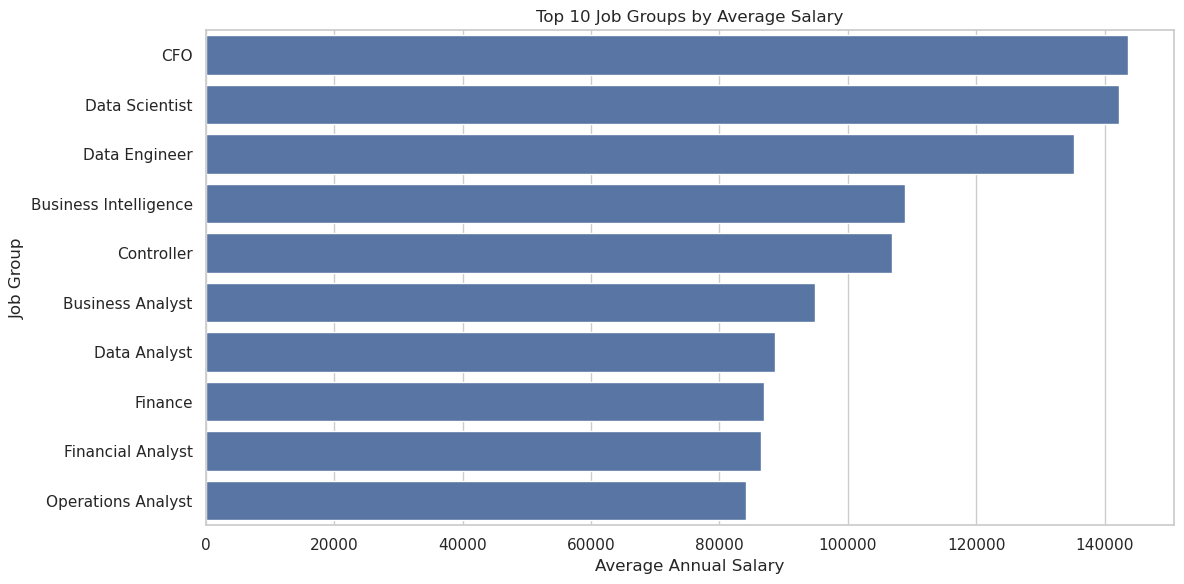

In [39]:
#top job groups by average salary
#group data by job group and calculate mean salary and count for each group
job_group_salary = (
    df.groupby(job_group_col)[salary_col]
    .agg(["mean", "count"])
    .reset_index()
)

#only keep groups with enough data
job_group_salary = job_group_salary[job_group_salary["count"] >= 20]

#sort job groups by average salary from highest to lowest and keep top 10
top_job_groups = job_group_salary.sort_values("mean", ascending=False).head(10)

plt.figure(figsize=(12, 6))
#creates horizontal bar chart of top job groups
sns.barplot(data=top_job_groups, x="mean", y=job_group_col)

plt.title("Top 10 Job Groups by Average Salary")
plt.xlabel("Average Annual Salary")
plt.ylabel("Job Group")

plt.tight_layout()
plt.show()

### Graph 10: Job Group Fairness Analysis
##### This graph shows the 10 job groups with the highest average fairness index. It helps identify which job categories have company reported salaries that are closest to or above the BLS expected salary.

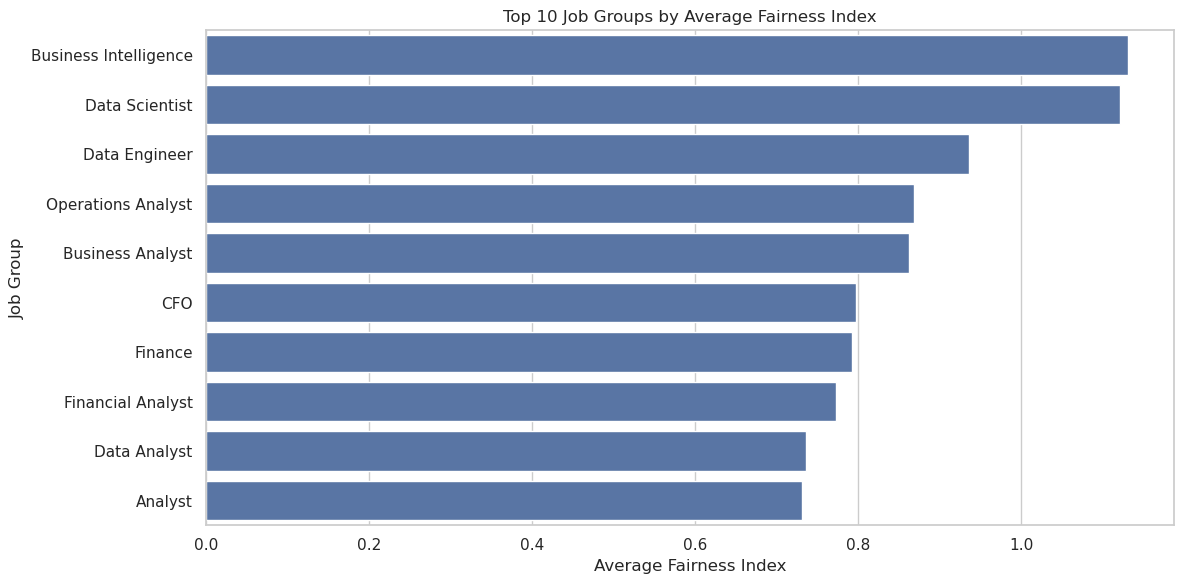

In [40]:
#top job groups by average fairness index
#group data by job group and calculate mean fairness index and count for each
job_group_fairness = (
    df.groupby(job_group_col)["fairness_index"]
    .agg(["mean", "count"])
    .reset_index()
)
#only keeps job records with 20 records
job_group_fairness = job_group_fairness[job_group_fairness["count"] >= 20]

#sorts job groups from highest to lowest and keeps 10
top_fair_groups = job_group_fairness.sort_values("mean", ascending=False).head(10)

plt.figure(figsize=(12, 6))
#creates horizontal bar chart of top job groups by fairness index
sns.barplot(data=top_fair_groups, x="mean", y=job_group_col)

plt.title("Top 10 Job Groups by Average Fairness Index")
plt.xlabel("Average Fairness Index")
plt.ylabel("Job Group")

plt.tight_layout()
plt.show()

### Graph 11: Remote vs. On-Site Salary
##### This graph compares salary distributions across on site, remote, and hybrid jobs. It shows differences in median salary, salary spread, and outliers for each work arrangement.

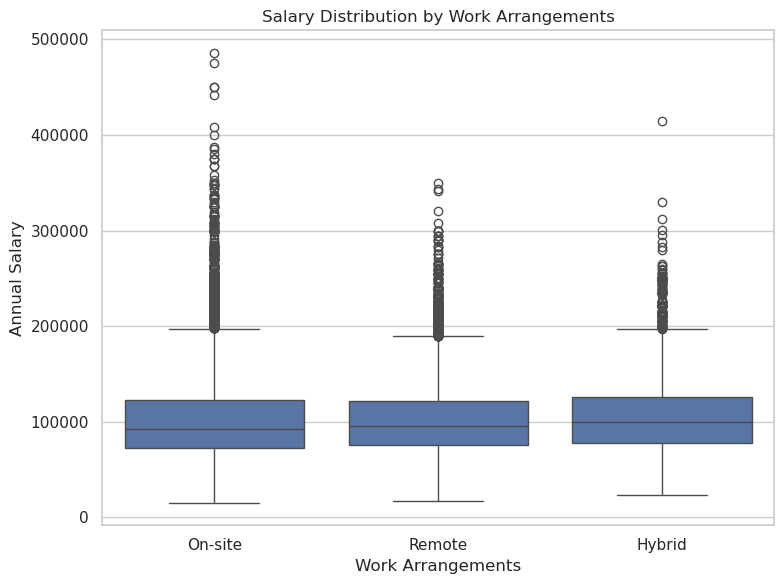

In [42]:
plt.figure(figsize=(8, 6))

#creates boxplot comparing salaries across different work arrangements
sns.boxplot(
    data=df,
    x="remote",
    y=salary_col
)

plt.title("Salary Distribution by Work Arrangements")
plt.xlabel("Work Arrangements")
plt.ylabel("Annual Salary")

plt.tight_layout()
plt.show()

### Graph 12: Correlation Heatmap
##### This heatmap shows the correlation between the numeric variables in the dataset. It helps identify which variables move together, such as company salary measures being strongly related to each other and the fairness index being strongly related to company-reported salary.

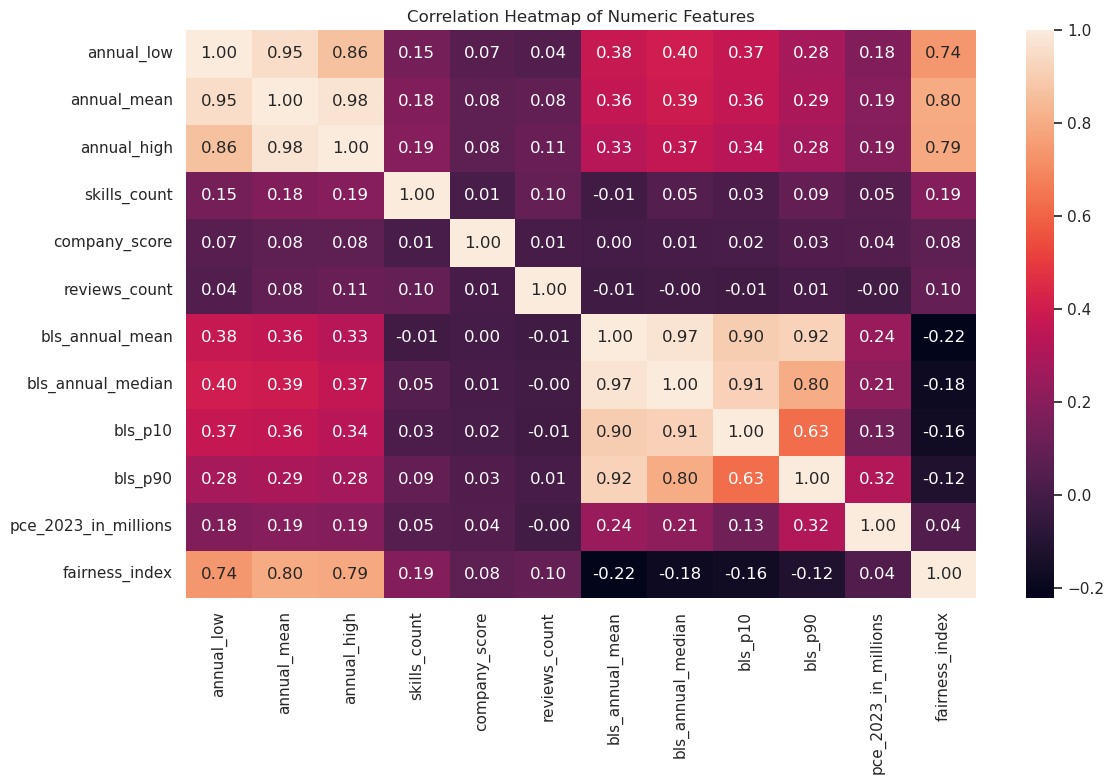

In [43]:
#list of numeric columns to include in correlation analysis, all of these columns contain numbers 
numeric_cols = [
    "annual_low",
    "annual_mean",
    "annual_high",
    "skills_count",
    "company_score",
    "reviews_count",
    "bls_annual_mean",
    "bls_annual_median",
    "bls_p10",
    "bls_p90",
    "pce_2023_in_millions",
    "fairness_index"
]

#creates new datafram using selected numeric columns
numeric_df = df[numeric_cols].copy()

#calculates correlation matrix between all numeric columns with correlation values ranging from -1 to 1. close to 1 means two varaibles increase together, close to -1 means one increases while other decreases, and close to 0 means there is no relationship
corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
#creates heatmap using correlation matrix
sns.heatmap(corr, annot=True, fmt=".2f")

plt.title("Correlation Heatmap of Numeric Features")

plt.tight_layout()
plt.show()

### Summary by fairness category
##### This table summarizes the dataset by fairness category. It compares how many jobs fall into each category and shows the average company salary, BLS expected salary, fairness index, and cost-of-living proxy for each group.

In [44]:
#summary table by fairness label
summary_table = (
    df.groupby(label_col)
    .agg(
        count=(salary_col, "count"),
        avg_salary=(salary_col, "mean"),
        avg_expected_salary=(expected_salary_col, "mean"),
        avg_fairness_index=(fairness_col, "mean"),
        avg_cost_of_living=(cost_col, "mean")
    )
    .reset_index()
)

summary_table

,fairness_label,count,avg_salary,avg_expected_salary,avg_fairness_index,avg_cost_of_living
0,Fair,6012,120624.647056,121923.502994,0.989687,1.041207e+06
1,Generous,5846,162260.370287,119878.159425,1.358495,1.130350e+06
2,Underpaid,24594,84111.988892,132040.378141,0.646705,1.029870e+06


### Summary by state
##### This table summarizes salary and fairness metrics by state. It shows the number of jobs in each state, average company salary, average BLS expected salary, average fairness index, and average PCE value, sorted by the states with the highest fairness index.

In [45]:
#state summary table
state_summary = (
    df.groupby(state_col)
    .agg(
        count=(salary_col, "count"),
        avg_salary=(salary_col, "mean"),
        avg_expected_salary=(expected_salary_col, "mean"),
        avg_fairness_index=("fairness_index", "mean"),
        avg_pce=(cost_col, "mean")
    )
    .reset_index()
    .sort_values("avg_fairness_index", ascending=False)
)

state_summary.head(10)

,state_x,count,avg_salary,avg_expected_salary,avg_fairness_index,avg_pce
25,MS,61,89744.762295,90663.934426,0.989446,123851.1
2,AR,104,87695.692308,96260.576923,0.917196,135760.8
7,DC,818,116015.191809,130961.259169,0.901444,62490.4
32,NM,276,86902.601812,98932.318841,0.892243,97420.9
6,CT,478,118056.735356,133351.987448,0.885322,235580.4
42,TN,383,97607.419582,110924.934726,0.884264,351524.5
11,HI,84,91575.011905,107341.904762,0.879390,83403.5
29,NE,166,88437.874699,103785.060241,0.870663,103226.1
39,RI,149,98603.917450,118248.859060,0.868011,61337.8
4,CA,7021,120159.826720,140924.022219,0.866309,2526290.3
